# Project #3 - Regularization using CV

## 1 Setup

### 1.1 Libraries

#### Import Libraries

In [1]:
# Data manipulation libraries.
import numpy as np
import pandas as pd

# Data visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Data modeling libraries.
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import r2_score

#### Configure Libraries

In [2]:
RANDOM_STATE = 0

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Pandas.
pd.options.display.width = 100
pd.options.display.max_columns = None

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

### 1.2 Dataset

#### Import Dataset

In [3]:
add_df = pd.read_csv("data/advertising.csv")

display(add_df.sample(5, random_state=rng))

row_count, col_count = add_df.shape
print(f"Dataset contains {row_count:,} rows and {col_count} columns.")

,TV,Radio,Newspaper,Sales
125,87.2,11.8,25.9,10.6
101,296.4,36.3,100.9,23.8
53,182.6,46.2,58.7,21.2
61,261.3,42.7,54.7,24.2
166,17.9,37.6,21.6,8.0


Dataset contains 200 rows and 4 columns.


#### Metadata

In [4]:
add_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


## 2 Base Model

### 2.1 Training Setup

#### Split Features and Target

In [5]:
target = "Sales"
X = add_df.drop(columns=target)
y = add_df[target]

X.shape, y.shape

((200, 3), (200,))

#### Train Test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((140, 3), (60, 3), (140,), (60,))

#### CV Strategy

In [7]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv

KFold(n_splits=3, random_state=0, shuffle=True)

### 2.2 Training Pipeline

#### OLS Training Pipeline

In [8]:
base_pl = Pipeline(
    steps=[
        ("std_scaler", StandardScaler()),
        ("OLS_estimator", LinearRegression()),
    ]
).set_output(transform="pandas")

base_pl.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('std_scaler', ...), ('OLS_estimator', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


#### Feature Importance (Base Model)

In [9]:
fi_df2 = (
    pd.DataFrame(
        data={
            "Feature": base_pl.feature_names_in_,
            "Importance": np.abs(base_pl.named_steps["OLS_estimator"].coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top important features:")
fi_df2

Top important features:


,Feature,Importance
0,TV,4.501522
1,Radio,1.686647
2,Newspaper,0.042087


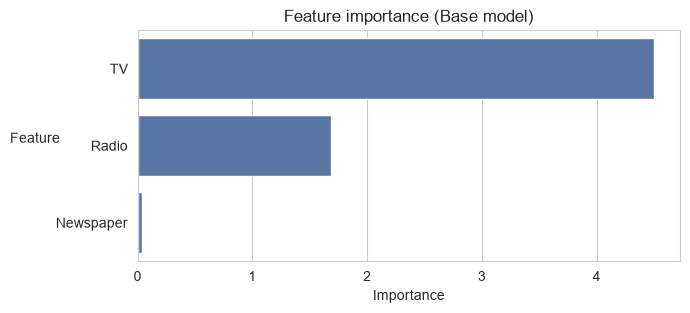

In [10]:
plt.figure(figsize=(7, 3))

sns.barplot(fi_df2, x="Importance", y="Feature")
plt.title("Feature importance (Base model)")
plt.ylabel("Feature", rotation=0, labelpad=15)

plt.show()

#### Training R-squared

In [11]:
base_tr_r2 = base_pl.score(X_train, y_train)
print("Base model Train R-squared value:", round(base_tr_r2, 6))

Base model Train R-squared value: 0.915993


#### Testing R-squared

In [12]:
base_ts_r2 = base_pl.score(X_test, y_test)
print("Base model Test R-squared value:", round(base_ts_r2, 6))

Base model Test R-squared value: 0.869205


#### Observations

1. Base model is trained without any Polynomial features and using default model configuration.
2. Base model is overfitting since the gap between Train and Test R-squared is large.
3. Feature _TV_ is more important that _Radio_ is more important that _Newspaper_ in predicting sales.

> **Note**:
>
> OLS model does not have any hyperparameters.

## 3 Lasso Regression

### 3.1 Training Pipeline

#### Lasso Regression Training Pipeline

In [13]:
lreg_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Lasso_estimator", Lasso(random_state=RANDOM_STATE)),
    ]
).set_output(transform="pandas")

lreg_pl.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly_features', ...), ('std_scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


#### Feature Importance (Lasso Regression)

In [14]:
fi_df3 = (
    pd.DataFrame(
        data={
            "Feature": lreg_pl.named_steps["poly_features"].get_feature_names_out(),
            "Importance": np.abs(lreg_pl.named_steps["Lasso_estimator"].coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 important features:")
fi_df3.head()

Top 5 important features:


,Feature,Importance
0,TV,2.609433
1,TV Radio,1.592756
2,Radio,0.000000
3,Newspaper,0.000000
4,TV^2,0.000000


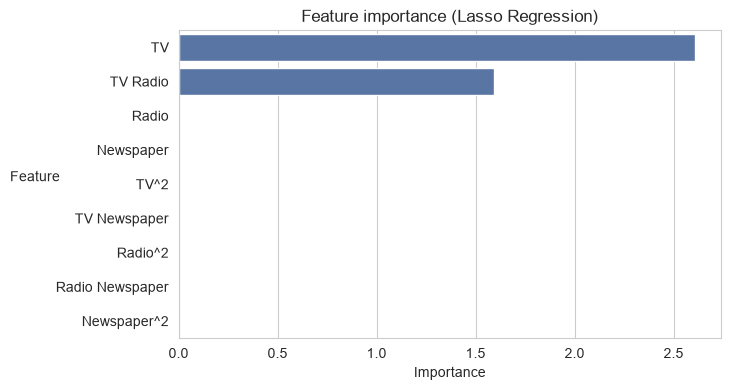

In [15]:
plt.figure(figsize=(7, 4))

sns.barplot(fi_df3, x="Importance", y="Feature")
plt.title("Feature importance (Lasso Regression)")
plt.ylabel("Feature", rotation=0, labelpad=15)

plt.show()

#### Training R-squared

In [16]:
lreg_tr_r2 = lreg_pl.score(X_train, y_train)
print("Lasso Regression Train R-squared value:", round(lreg_tr_r2, 6))

Lasso Regression Train R-squared value: 0.874372


#### Testing R-squared

In [17]:
lreg_ts_r2 = lreg_pl.score(X_test, y_test)
print("Lasso Regression Test R-squared value:", round(lreg_ts_r2, 6))

Lasso Regression Test R-squared value: 0.830037


### 3.2 Hyperparameter Tuning

#### Hyperparameter: Regularization parameter lambda

In [18]:
lambdas = np.linspace(0.0001, 0.1, 20)
tr_errors = list()
ts_errors = list()
for alpha in lambdas:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Lasso_estimator", Lasso(alpha=alpha, max_iter=10_000, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

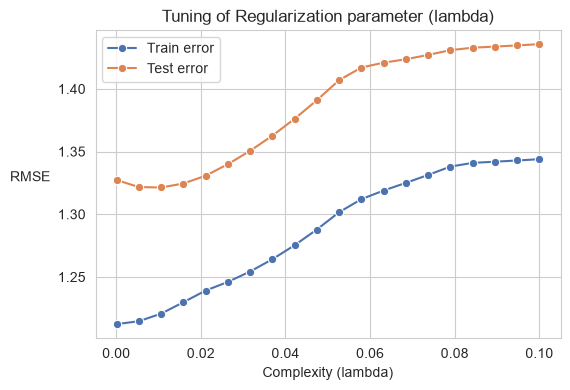

In [19]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=lambdas, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=lambdas, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning of Regularization parameter (lambda)")
plt.xlabel("Complexity (lambda)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

#### Hyperparameter: Polynomial Degree

In [20]:
degrees = [1, 2, 3, 4, 5, 6, 7, 8]
tr_errors = list()
ts_errors = list()
for degree in degrees:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=degree, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Lasso_estimator", Lasso(alpha=0.01, max_iter=3_000, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

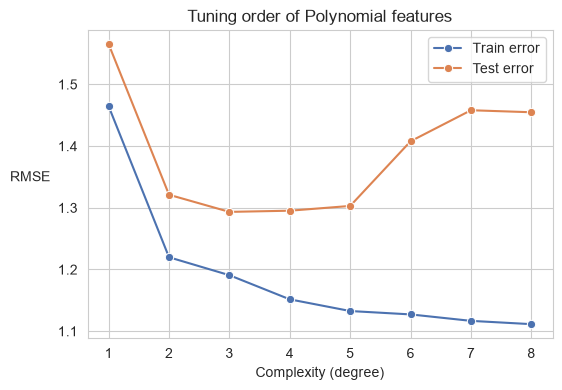

In [21]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=degrees, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=degrees, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning order of Polynomial features")
plt.xlabel("Complexity (degree)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

### 3.3 Lasso Final Model

#### Lasso Regression Final pipeline

In [22]:
lreg_final_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Lasso_estimator", Lasso(alpha=0.01, max_iter=3_000, random_state=RANDOM_STATE)),
    ]
)

lreg_final_pl.fit(X_train, y_train)

lreg_tr_r2 = lreg_final_pl.score(X_train, y_train)
print("Lasso Regression Train R-squared value:", round(lreg_tr_r2, 6))
lreg_ts_r2 = lreg_final_pl.score(X_test, y_test)
print("Lasso Regression Test R-squared value:", round(lreg_ts_r2, 6))

Lasso Regression Train R-squared value: 0.941166
Lasso Regression Test R-squared value: 0.912505


## 4 Ridge Regression

### 4.1 Training Pipeline

#### Ridge Regression Training Pipeline

In [23]:
rreg_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Ridge_estimator", Ridge(random_state=RANDOM_STATE)),
    ]
).set_output(transform="pandas")

rreg_pl.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly_features', ...), ('std_scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


#### Feature Importance (Ridge Regression)

In [24]:
fi_df4 = (
    pd.DataFrame(
        data={
            "Feature": rreg_pl.named_steps["poly_features"].get_feature_names_out(),
            "Importance": np.abs(rreg_pl.named_steps["Ridge_estimator"].coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 important features:")
fi_df4.head()

Top 5 important features:


,Feature,Importance
0,TV,5.084844
1,TV^2,1.436468
2,TV Radio,1.324976
3,Radio^2,1.193754
4,Radio,0.409502


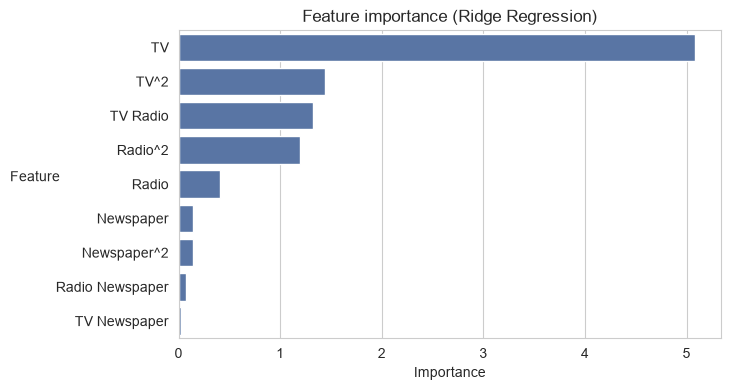

In [25]:
plt.figure(figsize=(7, 4))

sns.barplot(fi_df4, x="Importance", y="Feature")
plt.title("Feature importance (Ridge Regression)")
plt.ylabel("Feature", rotation=0, labelpad=15)

plt.show()

#### Training R-squared

In [26]:
rreg_tr_r2 = rreg_pl.score(X_train, y_train)
print("Ridge Regression Train R-squared value:", round(rreg_tr_r2, 6))

Ridge Regression Train R-squared value: 0.940417


#### Testing R-squared

In [27]:
rreg_ts_r2 = rreg_pl.score(X_test, y_test)
print("Ridge Regression Test R-squared value:", round(rreg_ts_r2, 6))

Ridge Regression Test R-squared value: 0.908445


### 4.2 Hyperparameter Tuning

#### Hyperparameter: Regularization parameter lambda

In [28]:
lambdas = np.linspace(0.00001, 0.1, 20)
tr_errors = list()
ts_errors = list()
for alpha in lambdas:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Ridge_estimator", Ridge(alpha=alpha, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

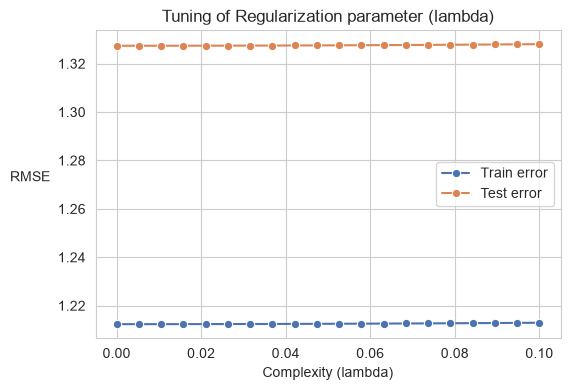

In [29]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=lambdas, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=lambdas, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning of Regularization parameter (lambda)")
plt.xlabel("Complexity (lambda)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

#### Hyperparameter: Polynomial Degree

In [30]:
degrees = [1, 2, 3, 4, 5, 6]
tr_errors = list()
ts_errors = list()
for degree in degrees:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=degree, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Ridge_estimator", Ridge(alpha=0.00001, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

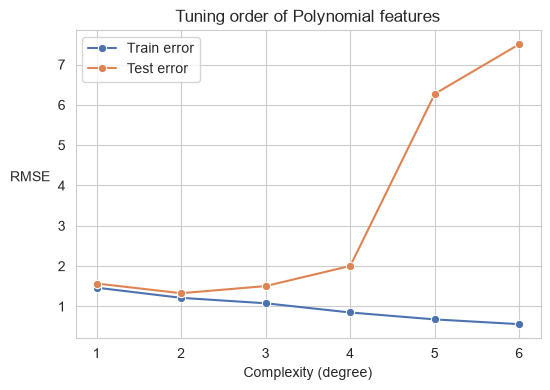

In [31]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=degrees, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=degrees, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning order of Polynomial features")
plt.xlabel("Complexity (degree)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

### 4.3 Ridge Final Model

#### Ridge Regression Final pipeline

In [32]:
rreg_final_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Ridge_estimator", Ridge(alpha=0.00001, random_state=RANDOM_STATE)),
    ]
)

rreg_final_pl.fit(X_train, y_train)

rreg_tr_r2 = rreg_final_pl.score(X_train, y_train)
print("Ridge Regression Train R-squared value:", round(rreg_tr_r2, 6))

rreg_ts_r2 = rreg_final_pl.score(X_test, y_test)
print("Ridge Regression Test R-squared value:", round(rreg_ts_r2, 6))

Ridge Regression Train R-squared value: 0.942001
Ridge Regression Test R-squared value: 0.914802


## 5 Elastic net

### 5.1 Training Pipeline

#### Elastic Net Training Pipeline

In [33]:
enet_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Enet_estimator", ElasticNet(random_state=RANDOM_STATE)),
    ]
).set_output(transform="pandas")

enet_pl.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly_features', ...), ('std_scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


#### Feature Importance (Elastic Net)

In [34]:
fi_df5 = (
    pd.DataFrame(
        data={
            "Feature": enet_pl.named_steps["poly_features"].get_feature_names_out(),
            "Importance": np.abs(enet_pl.named_steps["Enet_estimator"].coef_),
        }
    )
    .sort_values(by="Importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 5 important features:")
fi_df5.head()

Top 5 important features:


,Feature,Importance
0,TV,1.465707
1,TV Radio,1.226196
2,TV^2,1.003993
3,TV Newspaper,0.258852
4,Radio^2,0.215532


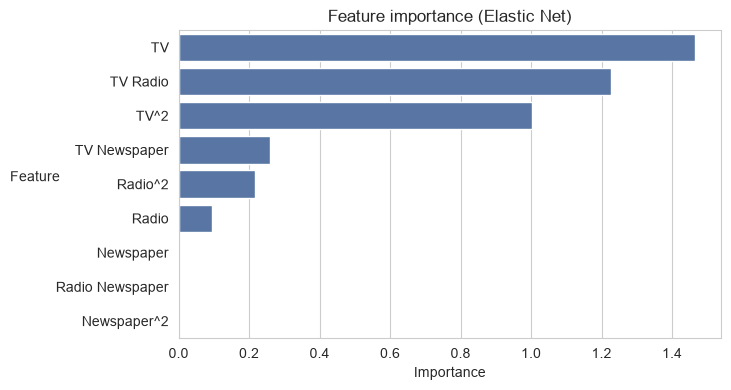

In [35]:
plt.figure(figsize=(7, 4))

sns.barplot(fi_df5, x="Importance", y="Feature")
plt.title("Feature importance (Elastic Net)")
plt.ylabel("Feature", rotation=0, labelpad=15)

plt.show()

#### Training R-squared

In [36]:
enet_tr_r2 = enet_pl.score(X_train, y_train)
print("Elastic Net Train R-squared value:", round(enet_tr_r2, 6))

Elastic Net Train R-squared value: 0.846051


#### Testing R-squared

In [37]:
enet_ts_r2 = enet_pl.score(X_test, y_test)
print("Elastic Net Test R-squared value:", round(enet_ts_r2, 6))

Elastic Net Test R-squared value: 0.786054


### 5.2 Hyperparameter Tuning

#### Hyperparameter: Regularization parameter lambda

In [38]:
lambdas = np.linspace(0.00001, 0.1, 20)
tr_errors = []
ts_errors = []
for alpha in lambdas:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Enet_estimator", ElasticNet(alpha=alpha, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

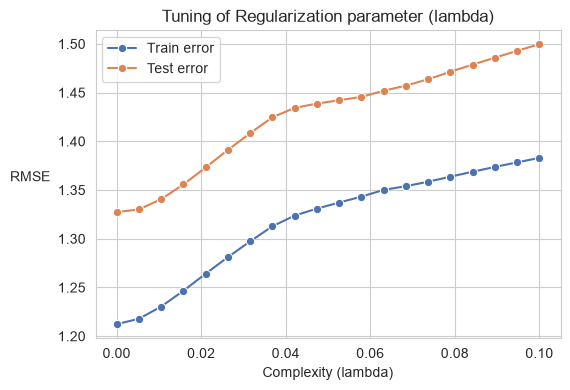

In [39]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=lambdas, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=lambdas, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning of Regularization parameter (lambda)")
plt.xlabel("Complexity (lambda)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

#### Hyperparameter: l1_ratio

In [40]:
l1rs = np.linspace(0.0, 0.5, 20)
tr_errors = []
ts_errors = []
for l1_ratio in l1rs:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Enet_estimator", ElasticNet(alpha=0.005, l1_ratio=l1_ratio, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

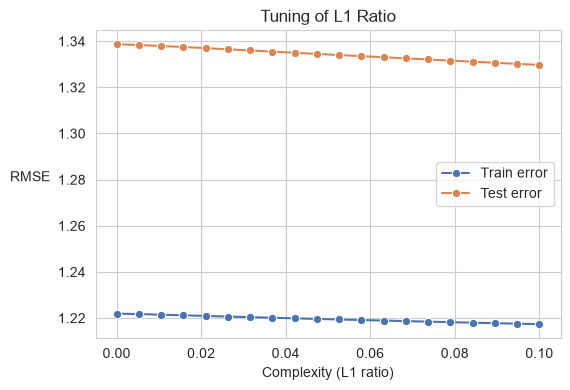

In [41]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=lambdas, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=lambdas, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning of L1 Ratio")
plt.xlabel("Complexity (L1 ratio)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

#### Hyperparameter: Polynomial Degree

In [42]:
degrees = [1, 2, 3, 4, 5, 6]
tr_errors = []
ts_errors = []
for degree in degrees:
    cv_pipeline = Pipeline(
        steps=[
            ("poly_features", PolynomialFeatures(degree=degree, include_bias=False)),
            ("std_scaler", StandardScaler()),
            ("Enet_estimator", ElasticNet(alpha=0.005, max_iter=8000, random_state=RANDOM_STATE)),
        ]
    )

    cv_result = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
    )

    tr_errors.append(-cv_result["train_score"].mean())
    ts_errors.append(-cv_result["test_score"].mean())

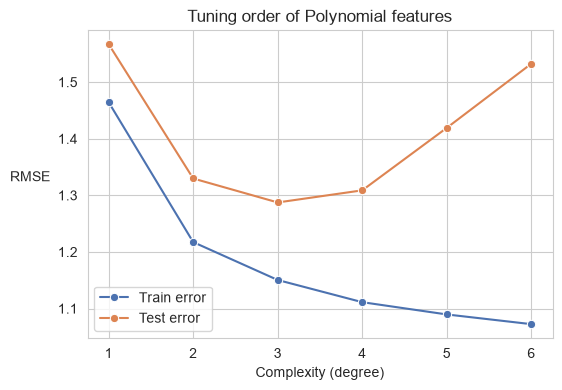

In [43]:
plt.figure(figsize=(6, 4))

sns.lineplot(x=degrees, y=tr_errors, marker="o", label="Train error")
sns.lineplot(x=degrees, y=ts_errors, marker="o", label="Test error")
plt.title("Tuning order of Polynomial features")
plt.xlabel("Complexity (degree)")
plt.ylabel("RMSE", rotation=0, labelpad=20)

plt.show()

### 5.3 Elastic Net Final Model

#### Elastic Net Final pipeline

In [44]:
enet_final_pl = Pipeline(
    steps=[
        ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
        ("std_scaler", StandardScaler()),
        ("Enet_estimator", ElasticNet(alpha=0.005, max_iter=8000, random_state=RANDOM_STATE)),
    ]
)

enet_final_pl.fit(X_train, y_train)

enet_tr_r2 = enet_final_pl.score(X_train, y_train)
print("Elastic Net Train R-squared value:", round(enet_tr_r2, 6))

enet_ts_r2 = enet_final_pl.score(X_test, y_test)
print("Elastic Net Test R-squared value:", round(enet_ts_r2, 6))

Elastic Net Train R-squared value: 0.941533
Elastic Net Test R-squared value: 0.912334
